<a href="https://www.kaggle.com/code/makrrc/0-95239-s0602-predicting-heart-disease?scriptVersionId=297947489" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

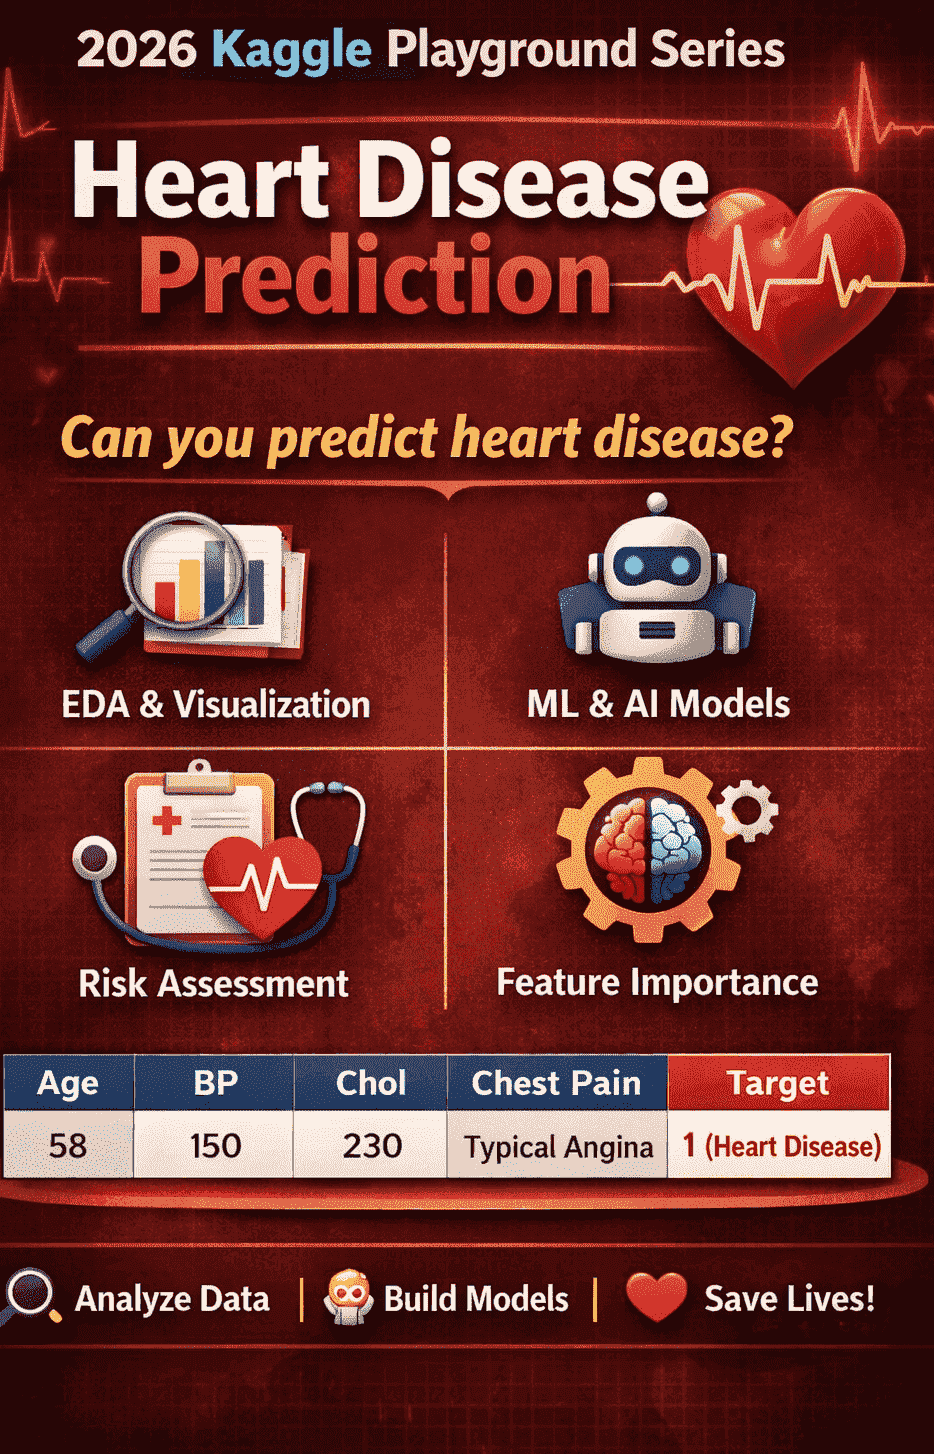

# About #original dataset

# Column Descriptions (Data Dictionary)

🫀 Heart_Disease_Prediction.csv contains clinical and demographic features used to predict whether a patient has heart disease.

Each row represents one individual, and each column describes a medical attribute such as age, blood pressure, cholesterol levels, chest pain type, ECG results, and more.

This file is mainly used for:

🤖 Binary classification (heart disease: 0 = No, 1 = Yes)

📊 Exploratory Data Analysis (EDA)

🧠 Machine learning model training

🩺 Risk assessment and medical research


🧬 Column Name	📝 Description <br>
🧓 Age	Age of the patient (in years) <br>
🚹 Sex	Gender of the patient (1 = Male, 0 = Female)<br>
💔 Chest pain type	Type of chest pain:<br>
🔹 1 = Typical angina<br>
🔹 2 = Atypical angina<br>
🔹 3 = Non-anginal pain<br>
🔹 4 = Asymptomatic<br>
💉 BP	Resting blood pressure (mm Hg)<br>
🧈 Cholesterol	Serum cholesterol level (mg/dL)<br>
🍬 FBS over 120	Fasting blood sugar > 120 mg/dL (1 = True, 0 = False)<br>
📈 EKG results	Resting electrocardiogram results:<br>
❤️ 0 = Normal<br>
⚠️ 1 = ST-T wave abnormality<br>
💥 2 = Left ventricular hypertrophy<br>
❤️ Max HR	Maximum heart rate achieved<br>
🏃 Exercise angina	Exercise-induced angina (1 = Yes, 0 = No)<br>
📉 ST depression	ST depression induced by exercise relative to rest<br>
⛰️ Slope of ST	Slope of the peak exercise ST segment<br>
🩸 Number of vessels fluro	Number of major vessels (0–3) colored by fluoroscopy<br>
🧬 Thallium	Thallium stress test result (categorical medical indicator)<br>
🎯 Heart Disease	Target variable:<br>
❤️ Presence = Heart disease detected<br>
💚 Absence = No heart disease<br>
🔢🧩 Encoding Notes<br>
✔ Categorical variables are numerically encoded 🔢 for ML compatibility 🤖<br>
✔ Target column uses text labels (Presence / Absence) for better interpretability 👁️<br>
✔ Dataset is ready for Logistic Regression 📐, Tree-based models 🌳, and Ensembles 🏆<br>

🧬📚 Source & Context<br>
This dataset follows standard clinical encodings commonly used in heart disease research,<br>
similar to datasets used in:<br>

🏥 Medical machine learning studies<br>
🎓 Academic projects<br>
🏆 Kaggle notebooks & benchmarks<br>
⚠️🚑 Disclaimer<br>
🚨 This dataset is intended ONLY for educational and research purposes.<br>
🚫 It must NOT be used for real-world medical diagnosis or treatment decisions without<br> professional clinical validation.<br>



# Risk factor

- High Collesterol <br>
- High Blood Pressure <br>
- Diabetes <br>
- Obesity <br>
- Mental health <br>
- Smoking<br>
- Phisical inactivity<br>
- Alcohol <br>
- Stress <br>
- Air pollution <br>
- Family history <br>
- Diabetes mellitus <br>
- Obesity <br>
- Genetics and family history
- Reproductive factor ( women ) <br>
-LDL (low-density lipoprotein) cholesterol, which is considered to be "bad" cholesterol because it can cause plaque buildup in your arteries.
HDL (high-density lipoprotein) cholesterol, which is considered to be "good" cholesterol because higher levels provide some protection against heart disease.<br>
-
-


# Risk factor references

https://www.ncbi.nlm.nih.gov/books/NBK554410/ <br>
https://www.bhf.org.uk/informationsupport/risk-factors <br>
https://www.cdc.gov/heart-disease/risk-factors/index.html <br>

# Import Libraries

In [ ]:
import pandas as pd

In [ ]:
from sklearn.preprocessing import FunctionTransformer
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.preprocessing import LabelEncoder
from sklearn.preprocessing import OrdinalEncoder

In [ ]:
from sklearn.ensemble import RandomForestClassifier
# from sklearn.ensemble import StackingClassifier
from sklearn.inspection import permutation_importance
from sklearn.base import is_classifier

In [ ]:
# from sklearn.ensemble import StackingRegressor
from sklearn.ensemble import StackingClassifier
from sklearn.linear_model import RidgeClassifierCV
from sklearn.linear_model import Perceptron
# from sklearn.linear_model import LogisticRegression
from xgboost import XGBClassifier
from sklearn.ensemble import ExtraTreesClassifier
# from sklearn.svm import SVR
from sklearn.svm import LinearSVR
from sklearn.svm import LinearSVC
from sklearn import linear_model

In [ ]:
from sklearn.linear_model import SGDClassifier
from sklearn.linear_model import LogisticRegression

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

In [ ]:
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

In [ ]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Loading the databases.

In [ ]:
train = pd.read_csv('/kaggle/input/playground-series-s6e2/train.csv')
test = pd.read_csv('/kaggle/input/playground-series-s6e2/test.csv')

In [ ]:
# # Download latest version
# #original = pd.read_csv("/kaggle/input/heartdisease/Heart_Disease_Prediction.csv") 
# #original

# Functions for manipulating datasets and creating functional features.

In [ ]:
le = LabelEncoder()
def CodificarLabelEncode(Dataset, columns, LabelEncoder):
    LabelEncoder.fit(Dataset[columns])
    Dataset['le_'+columns] = le.transform(Dataset[columns])
    return Dataset

In [ ]:
oe = OrdinalEncoder()

def CodificarOrdinalEncoder(dataset, column, encoder):
    """
    Codifica uma coluna categórica usando OrdinalEncoder e
    adiciona uma nova coluna codificada ao DataFrame.
    """
    # O erro estava aqui: precisamos passar [[column]] para garantir 2D
    encoder.fit(dataset[[column]])  
    dataset['oe_' + column] = encoder.transform(dataset[[column]])
    return dataset

In [ ]:
def get_dummies1(dataset, column):
    result = ''
    for elemento in column:
        print(elemento)
        temp = pd.get_dummies(dataset[elemento])
        dataset = pd.concat([dataset, temp], axis=1)
    return dataset  

In [ ]:
def get_bool1(dataset, column, yes, no):
    temp = dataset[column].replace({yes:1,no:0})
    temp = temp
    return temp

In [ ]:
def get_feature_importance(
    model,
    X: pd.DataFrame,
    y=None,
    top_k=None,
    method="auto",
    scoring="roc_auc",
    random_state=42
):
    """
    Retorna um DataFrame com as importâncias das features.

    Parameters
    ----------
    model : modelo sklearn treinado
    X : DataFrame de features
    y : target (obrigatório para permutation_importance)
    top_k : int | None
        Retorna apenas as top_k features
    method : 'auto' | 'tree' | 'linear' | 'permutation'
    scoring : métrica para permutation_importance
    """

    feature_names = X.columns.to_list()

    # 1️⃣ Árvores (RandomForest, XGB, etc.)
    if method in ["auto", "tree"] and hasattr(model, "feature_importances_"):
        importances = model.feature_importances_

    # 2️⃣ Lineares (LinearRegression, LogisticRegression)
    elif method in ["auto", "linear"] and hasattr(model, "coef_"):
        coef = model.coef_
        importances = np.abs(coef).ravel()

    # 3️⃣ Fallback universal → Permutation Importance
    else:
        if y is None:
            raise ValueError("y é obrigatório para permutation_importance")

        r = permutation_importance(
            model, X, y,
            n_repeats=10,
            scoring=scoring,
            random_state=random_state
        )
        importances = r.importances_mean

    # 4️⃣ DataFrame final
    df_importance = (
        pd.DataFrame({
            "feature": feature_names,
            "importance": importances
        })
        .sort_values("importance", ascending=False)
        .reset_index(drop=True)
    )

    if top_k:
        df_importance = df_importance.head(top_k)

    return df_importance

In [ ]:
def plot_target_hue(df, column, target_column):
    plt.figure(figsize=(18,6))
    sns.countplot(data=df, x=column, hue=target_column)
    plt.xticks(rotation=90)
    plt.title(f'{column} vs {target_column}')
    plt.show()

In [ ]:
def plot_target_comparison(df, column, target_column):
    """
    Plot comparison between:

    - Total number of records per category
    
    - Total number of positive cases per category
    
    Parameters:
    
    df (DataFrame)
    column (str) -> categorical or discrete column
    target_column (str) -> binary column (0 and 1)
    """
    
    # Total records by category
    total = df.groupby(column)[target_column].count()
    
    # Total positives by category
    positive = df.groupby(column)[target_column].sum()
    
    # Creating a consolidated DataFrame
    resumo = pd.DataFrame({
        'Total Records': total,
        'Total Records': positive
    }).reset_index()
    
    # Sort by total records (optional)
    resumo = resumo.sort_values(by='Total Records', ascending=False)
    
    # Plot
    plt.figure(figsize=(12,6))
    
    sns.barplot(data=resumo, x=column, y='Total Records', alpha=0.6)
    sns.barplot(data=resumo, x=column, y='Total Records')
    
    plt.xticks(rotation=45)
    plt.title(f'Distribuição de {column} vs {target_column}')
    plt.ylabel('Amount')
    plt.show()
    
    return resumo

In [ ]:
def make_pipeline(model, features):
    return Pipeline([
        ('select', ColumnTransformer(
            [('sel', 'passthrough', features)],
            remainder='drop'
        )),
        ('model', model)
    ])

# EDA - Exploratory Data analisys

In [ ]:
train.info()

In [ ]:
train.describe()

In [ ]:
train.dtypes

In [ ]:
train.isna().sum()

In [ ]:
plt.figure(figsize=(18,6))
sns.heatmap( train.loc[:, train.dtypes != 'object'].corr(), annot=True )

Looking at the two maps, we discovered that some correlations were lost when the new dataset was created. How can we reuse these correlations to generate a better model?

In [ ]:
train[ 'Heart Disease' ].unique()

In [ ]:
train[ 'Heart Disease' ].value_counts()

In [ ]:
sns.barplot(train[ 'Heart Disease' ].value_counts())

By examining this graph, we can see that there are more records showing the absence of heart disease than the presence of heart disease.

In [ ]:
train['Heart Disease_numeric']=get_bool1(train, 'Heart Disease', 'Presence','Absence')
train

In [ ]:
plt.figure(figsize=(18,6))
sns.heatmap( train.loc[:, train.dtypes != 'object'].corr(), annot=True )

In [ ]:
train.loc[:, train.dtypes != 'object' ]

In [ ]:
train

# Analyze the Age field

In [ ]:
train.loc[:6,['Heart Disease_numeric', 'Age']]

In [ ]:
# Aumentar tamanho do gráfico: 12 polegadas de largura e 6 de altura
plt.figure(figsize=(12, 16))

# Create a bar plot
sns.countplot(y="Age", 
              data=train[['Heart Disease_numeric', 'Age']], 
              hue='Heart Disease_numeric', width=0.5, native_scale=True)

# Rotate the x-axis labels
plt.xticks(rotation=90, ha='right')

# Display the plot
plt.show()

As we can see, there have been a greater number of cases in recent years. But we also observed that the sample size varies significantly by age. Some age groups have many more samples, making it difficult to understand if there is a real correlation with age or if the increase is simply due to the larger sample size.

In [ ]:
casos_presentes = (
    train[train['Heart Disease_numeric'] == 1]
    .groupby('Age')
    .size()
)
# casos_presentes

In [ ]:
casos_nao_presentes = (
    train[train['Heart Disease_numeric'] == 0]
    .groupby('Age')
    .size()
)
# casos_nao_presentes

In [ ]:
# quadro_idade_percentual = pd.DataFrame({"":""})

In [ ]:
quadro_idade_percentual = pd.DataFrame({ })

In [ ]:
quadro_idade_percentual = pd.DataFrame({
    "casos_presentes": casos_presentes,
    "casos_nao_presentes": casos_nao_presentes
})

In [ ]:
quadro_idade_percentual['taxa_casos_presente_sobre_total'] = (
    quadro_idade_percentual['casos_presentes'] /
    (quadro_idade_percentual['casos_presentes'] +
     quadro_idade_percentual['casos_nao_presentes'])
)

quadro_idade_percentual

In [ ]:
quadro_idade_percentual.loc[quadro_idade_percentual.casos_nao_presentes.isna(), ['casos_nao_presentes','taxa_casos_presente_sobre_total'] ] = 0

In [ ]:
quadro_idade_percentual.sort_values('taxa_casos_presente_sobre_total', ascending= False)

In [ ]:
sns.histplot(data=train, x="Age", y="Heart Disease", hue="Heart Disease_numeric", multiple="stack", kde=True, bins=30)
plt.title("Age Distribution by Heart Disease")
plt.show()

It would be interesting to create a column that captures the highest probability as age increases.

In [ ]:
quadro_idade_percentual = quadro_idade_percentual.reset_index()

In [ ]:
quadro_idade_percentual[['Age','taxa_casos_presente_sobre_total']]

In [ ]:
train = pd.merge(train, quadro_idade_percentual, on='Age', how='inner')
train

In [ ]:
test = pd.merge(test, quadro_idade_percentual, on='Age', how='left')
test

In [ ]:
test.isna().sum()

In [ ]:
test.loc[ test['taxa_casos_presente_sobre_total'].isna(), 'casos_nao_presentes' ] = 0

In [ ]:
test.loc[ test['casos_presentes'].isna(), 'casos_presentes' ] = test[test['Age'] == 34 ][['casos_presentes']].mode()['casos_presentes']

In [ ]:
test.loc[ test['casos_presentes'].isna(), 'casos_presentes' ] = int(test.loc[test['Age'] == 34 ][['casos_presentes']].mode()['casos_presentes'][0])

In [ ]:
test.loc[ test['casos_nao_presentes'].isna(), 'casos_nao_presentes' ] = int(test.loc[test['Age'] == 34 ][['casos_nao_presentes']].mode()['casos_nao_presentes'][0])

In [ ]:
test.loc[ test['taxa_casos_presente_sobre_total'].isna(), 'taxa_casos_presente_sobre_total' ] = int(test.loc[test['Age'] == 34 ][['taxa_casos_presente_sobre_total']].mode()['taxa_casos_presente_sobre_total'][0])

In [ ]:
test.isna().sum()

In [ ]:
# test[test['Age'] == 34 ][['casos_presentes','casos_nao_presentes','taxa_casos_presente_sobre_total']]

Now that we've created the age-based feature, we can move on to the next columns.

# Analyze the Sex field

Let's see if there's a relationship between the participant's sex and having heart disease.<br>
Because we have an unbalanced sample between males and females, we cannot simply calculate a rate of present cases over the total. Instead, we must calculate the total number of present cases of each gender divided by the total number of cases of the same gender.

In [ ]:
train.loc[train['Sex']==1,['Sex','Heart Disease_numeric']].value_counts() / train[['Sex']].value_counts()[1]

In [ ]:
sex_heart_disease = {"female":train.loc[train['Sex']==0,['Sex','Heart Disease_numeric']].value_counts() / train[['Sex']].value_counts()[0]}
sex_heart_disease

In [ ]:
sex_heart_disease['male'] = train.loc[train['Sex']==1,['Sex','Heart Disease_numeric']].value_counts() / train[['Sex']].value_counts()[0]
sex_heart_disease

In [ ]:
train.loc[train['Sex']==0,['Sex','Heart Disease_numeric']].value_counts() / train[['Sex']].value_counts()[0]

In [ ]:
sex_heart_disease_resume = pd.DataFrame({"male":sex_heart_disease['male'][1],"female":sex_heart_disease['female'][0]})
sex_heart_disease_resume

In [ ]:
# Create a figure and a set of subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5)) # fig size is optional

# Create the pie chart with percentages
ax1.pie(x=sex_heart_disease_resume['male'], labels=['absence','presence'], autopct='%1.1f%%', startangle=90)
ax1.set_title('male')
# ax1.title('male')
ax2.pie(x=sex_heart_disease_resume['female'], labels=['absence','presence'], autopct='%1.1f%%', startangle=90)
ax2.set_title('female')
# ax2.title('female')
# Ensure the pie chart is drawn as a circle
# plt.axis('equal') 

# plt.title("Percentage Heart disease by sex")
plt.show()


As we can see, there is a higher rate of positive cases among men is greater than among women, as we can see above.
It can increase the chances of heart disease.

In [ ]:
sex_heart_disease_resume = pd.DataFrame({"male":sex_heart_disease['male'][1],"female":sex_heart_disease['female'][0]})
sex_heart_disease_resume

# Analyze the Chest pain type field

In [ ]:
train['Chest pain type'].unique()

In [ ]:
train.loc[ train['Heart Disease_numeric'] == 0,['Chest pain type','Heart Disease_numeric']].groupby('Chest pain type').value_counts()

In [ ]:
train.loc[ train['Heart Disease_numeric'] == 1,['Chest pain type','Heart Disease_numeric']].groupby('Chest pain type').value_counts()

In [ ]:
chest_pain_type = {
    "presence" : train.loc[ train['Heart Disease_numeric'] == 1,['Chest pain type','Heart Disease_numeric']].groupby('Chest pain type').value_counts()
                  }
chest_pain_type

In [ ]:
chest_pain_type["absence"]= train.loc[ train['Heart Disease_numeric'] == 0,['Chest pain type','Heart Disease_numeric']].groupby('Chest pain type').value_counts()
chest_pain_type["absence"]

In [ ]:
chest_pain_type['absence'] = pd.DataFrame({"absence":chest_pain_type['absence']})
chest_pain_type['absence']

In [ ]:
chest_pain_type['presence'] = pd.DataFrame({"presence":chest_pain_type['presence']})
chest_pain_type['presence']

In [ ]:
sns.barplot(data=chest_pain_type['presence'], x='Chest pain type', y='presence' )

In [ ]:
sns.barplot(data=chest_pain_type['absence'], x='Chest pain type', y='absence' )

Wow!!! Very promising!

Very good. Type 4 appears to be strongly linked to heart disease.

In [ ]:
train['level_Chest_pain_type'] = 0
test['level_Chest_pain_type'] = 0

In [ ]:
train.loc[train['Chest pain type'] == 1, 'level_Chest_pain_type'] = 1
train.loc[train['Chest pain type'] == 2, 'level_Chest_pain_type'] = 2
train.loc[train['Chest pain type'] == 4, 'level_Chest_pain_type'] = 3
train.loc[train['Chest pain type'] == 3, 'level_Chest_pain_type'] = 4
train

In [ ]:
test.loc[test['Chest pain type'] == 1, 'level_Chest_pain_type'] = 1
test.loc[test['Chest pain type'] == 2, 'level_Chest_pain_type'] = 2
test.loc[test['Chest pain type'] == 4, 'level_Chest_pain_type'] = 3
test.loc[test['Chest pain type'] == 3, 'level_Chest_pain_type'] = 4
test

In [ ]:
test['level_Chest_pain_type'].unique()

In [ ]:
train['level_Chest_pain_type'].unique()

# Analyze the BP field

In [ ]:
np.sort(train['BP'].unique())

In [ ]:
train[['BP','Heart Disease_numeric']].value_counts()

In [ ]:
bp = train[['BP','Heart Disease_numeric']].value_counts().to_frame()

In [ ]:
bp.reset_index()

In [ ]:
df_percent = train[['BP']].groupby('BP').value_counts().to_frame()
df_percent

In [ ]:
plot_target_hue(train[['BP','Heart Disease_numeric']], 'BP', 'Heart Disease_numeric')

We have some very interesting numbers above.

# Analyze the Cholesterol field
🧈 Cholesterol Serum cholesterol level (mg/dL)

In [ ]:
train[['Cholesterol','Heart Disease_numeric']].groupby('Cholesterol')['Heart Disease_numeric'].count().sort_values().reset_index()

In [ ]:
plot_target_hue(train.loc[train['Cholesterol']>0,['Cholesterol','Heart Disease_numeric']], 'Cholesterol', 'Heart Disease_numeric')

# Analyze the FBS over 120

💉 BP	Resting blood pressure (mm Hg)<br>
Fasting blood sugar > 120 mg/dL (1 = True, 0 = False)

In [ ]:
train['FBS over 120'].unique()

In [ ]:
sns.catplot(data=train, kind="bar", x='FBS over 120', y="Heart Disease_numeric")

In [ ]:
plot_target_hue(train[['FBS over 120','Heart Disease_numeric']], 'FBS over 120', 'Heart Disease_numeric')

So far I haven't found anything interesting in this column.

# Analyze the EKG results
📈 EKG results	Resting electrocardiogram results:<br>
❤️ 0 = Normal<br>
⚠️ 1 = ST-T wave abnormality<br>
💥 2 = Left ventricular hypertrophy<br>

In [ ]:
plot_target_hue(train[['EKG results','Heart Disease_numeric']], 'EKG results', 'Heart Disease_numeric')

In [ ]:
train['EKG results'].unique()

See, an increase in the ECG increases the likelihood of heart disease in this 2(second) option.

In [ ]:
train[['EKG results','Heart Disease_numeric']]

# Analyze the Max HR
❤️ Max HR Maximum heart rate achieved

In [ ]:
np.sort( train['Max HR'].unique() )

In [ ]:
plot_target_hue(train[['Max HR','Heart Disease_numeric']], 'Max HR', 'Heart Disease_numeric')

# Analyze the Exercise angina

In [ ]:
train['Exercise angina'].unique()

In [ ]:
plot_target_hue(train[['Exercise angina','Heart Disease_numeric']], 'Exercise angina', 'Heart Disease_numeric')

In [ ]:
train['Exercise angina']

In [ ]:
train.loc[train['Heart Disease_numeric'] == 1,:]

In [ ]:
plt.figure(figsize=(16,6))
sns.heatmap( train.loc[(train['Heart Disease_numeric'] == 1) , (train.dtypes != 'object') ].corr(), annot=True )

In [ ]:
train.loc[train['Heart Disease_numeric'] == 1].count()

In [ ]:
sns.histplot( data=train, x='Age', y='Heart Disease' )

In [ ]:
train.loc[:, 
(train.columns != 'Heart Disease') \
& (train.columns != 'Heart Disease_numeric')
& (train.columns != 'id')
& (train.columns != 'Age')
]

In [ ]:
X = train.loc[:, 
(train.columns != 'Heart Disease') \
& (train.columns != 'Heart Disease_numeric')
& (train.columns != 'id')
& (train.columns != 'Age')
]
X

In [ ]:
# only stop excution

In [ ]:
# # Suppress the warning at runtime
# import warnings
# from sklearn.utils.validation import UserWarning

# with warnings.catch_warnings():
#     warnings.simplefilter("ignore", category=UserWarning)A

# Train test split

In [ ]:
y = train[
'Heart Disease_numeric'
]

In [ ]:
y.shape

In [ ]:
 # Treine seu modelo aqui
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Split the data
from sklearn.model_selection import StratifiedKFold

In [ ]:
# n_splits=5 (padrão atual)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
skf.get_n_splits(X, y)

In [ ]:
test['id']

In [ ]:
# Create a submission file
sub = pd.DataFrame()
sub['id'] = test['id']
# sub['target'] = np.zeros_like(test['id'])
sub['target_xgbr'] = np.zeros_like(test['id'])
sub['target_etr'] = np.zeros_like(test['id'])
# sub['target_etr'] = np.zeros_like(test['id'])

In [ ]:
sub['target_clf'] = np.zeros_like(test['id'])

In [ ]:
sub['target_prp'] = np.zeros_like(test['id'])

In [ ]:
sub['target_svc'] = np.zeros_like(test['id'])

# XGBClassifier

In [ ]:
xgbr = XGBClassifier(
    eval_metric= "auc",
    objective= "binary:logistic",
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    random_state=42
)

In [ ]:
best_features_XGBClassfier = ''

In [ ]:
test.shape

In [ ]:
test

In [ ]:
for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    xgbr.fit(X_train, y_train)

    df_imp = get_feature_importance(xgbr, X_train, y_train, top_k=10)

    
    best_features_XGBClassfier = df_imp.query("importance > 0")["feature"].tolist()

    xgbr.fit(X_train[best_features_XGBClassfier], y_train)

    y_proba = xgbr.predict_proba(X_test[best_features_XGBClassfier])[:, 1]

    roc_auc_score_xgbr = roc_auc_score(y_test, y_proba)

    sub['target_xgbr'] += roc_auc_score_xgbr/kfold
    
    print(f"Fold {roc_auc_score_xgbr} treinado com sucesso.")

In [ ]:
# xgbr.fit(X_train[best_features_XGBClassfier], y_train)

In [ ]:
X.columns

In [ ]:
X_train.columns

In [ ]:
pipe_xgbr = make_pipeline(xgbr, best_features_XGBClassfier)

# ExtraTreesClassifier

In [ ]:
etr = ExtraTreesClassifier(n_estimators=100, random_state=0)

In [ ]:
best_features_ExtraTreesClassfier=''

In [ ]:
for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    etr.fit(X_train, y_train)

    df_imp = get_feature_importance(etr, X_train, y_train, top_k=10)

    
    best_features_ExtraTreesClassfier = df_imp.query("importance > 0")["feature"].tolist()

    etr.fit(X_train[best_features_ExtraTreesClassfier], y_train)

    y_proba = etr.predict_proba(X_test[best_features_ExtraTreesClassfier])[:, 1]

    roc_auc_score_etr = roc_auc_score(y_test, y_proba)

    sub['target_etr'] += roc_auc_score_etr/kfold
    
    print(f"Fold {roc_auc_score_etr} treinado com sucesso.")

In [ ]:
pipe_etr = make_pipeline(etr, best_features_ExtraTreesClassfier)

# RidgeClassifierCV

In [ ]:
from sklearn.frozen import FrozenEstimator

In [ ]:
# clf = RidgeClassifierCV(
#     alphas=[1e-3, 1e-2, 1e-1, 1]
# )

In [ ]:
from sklearn.calibration import CalibratedClassifierCV

In [ ]:
best_features_clf = ''

In [ ]:
for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


    base_model = RidgeClassifierCV(
        alphas=[1e-3, 1e-2, 1e-1, 1]
    )
        
    base_model.fit(X_train, y_train)
    
    clf = CalibratedClassifierCV(
        estimator=FrozenEstimator(base_model),
        method='isotonic'
    )

    
    clf.fit(X_train, y_train)
    
    df_imp = get_feature_importance(clf, X_train, y_train, top_k=10)

    
    best_features_clf = df_imp.query("importance > 0")["feature"].tolist()


    base_model.fit(X_train[best_features_clf], y_train)
    
    clf = CalibratedClassifierCV(
        estimator=FrozenEstimator(base_model),
        method='isotonic'
    )
    
    clf.fit(X_train[best_features_clf], y_train)

    y_proba = clf.predict_proba(X_test[best_features_clf])[:, 1]

    roc_auc_score_clf = roc_auc_score(y_test, y_proba)

    sub['target_clf'] += roc_auc_score_clf/kfold
    
    print(f"Fold {roc_auc_score_clf} treinado com sucesso.")

In [ ]:
pipe_clf = make_pipeline(clf, best_features_clf)

# Perceptron

In [ ]:
# prp = Perceptron(tol=1e-3, random_state=0)

In [ ]:
for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    base_model = Perceptron(tol=1e-3, random_state=0)
    
    base_model.fit(X_train, y_train)

    prp = CalibratedClassifierCV(
    estimator=FrozenEstimator(base_model),
    method='isotonic'
    )
    prp.fit(X_train, y_train)
    
    df_imp = get_feature_importance(prp, X_train, y_train, top_k=10)

    
    best_features_prp = df_imp.query("importance > 0")["feature"].tolist()


    base_model.fit(X_train[best_features_prp], y_train)
    
    prp = CalibratedClassifierCV(
        estimator=FrozenEstimator(base_model),
        method='isotonic'
    )
    
    
    prp.fit(X_train[best_features_prp], y_train)

    y_proba = prp.predict_proba(X_test[best_features_prp])[:, 1]

    roc_auc_score_prp = roc_auc_score(y_test, y_proba)

    sub['target_prp'] += roc_auc_score_prp/kfold
    
    print(f"Fold {roc_auc_score_prp} treinado com sucesso.")

In [ ]:
pipe_prp = make_pipeline(prp, best_features_prp)

# LinearSVC

In [ ]:
for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    base_model = LinearSVC(C=1.0, random_state=42, max_iter=3000)
    
    base_model.fit(X_train, y_train)

    svc = CalibratedClassifierCV(
    estimator=FrozenEstimator(base_model),
    method='isotonic'
    )
    svc.fit(X_train, y_train)
    
    df_imp = get_feature_importance(svc, X_train, y_train, top_k=10)

    
    best_features_svc = df_imp.query("importance > 0")["feature"].tolist()


    base_model.fit(X_train[best_features_svc], y_train)
    
    prp = CalibratedClassifierCV(
        estimator=FrozenEstimator(base_model),
        method='isotonic'
    )
    
    
    prp.fit(X_train[best_features_svc], y_train)

    y_proba = svc.predict_proba(X_test[best_features_svc])[:, 1]

    roc_auc_score_svc = roc_auc_score(y_test, y_proba)

    sub['target_svc'] += roc_auc_score_svc/kfold
    
    print(f"Fold {roc_auc_score_svc} treinado com sucesso.")

In [ ]:
pipe_svc = make_pipeline(svc, best_features_svc)

# StackingClassifier

In [ ]:
estimators = [
    ('xgbr', pipe_xgbr),
    ('etr', pipe_etr),
    ('clf', pipe_clf),
    ('prp', pipe_prp),
    ('svc', pipe_svc)
]

In [ ]:
pipe_clf

In [ ]:
# for kfold, (train_idx, test_idx) in enumerate(skf.split(X, y)):

#     X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
#     y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]


#     reg = StackingClassifier(
#         estimators=estimators,
#         final_estimator=LogisticRegression(),
#         stack_method='predict_proba'
#     )
#     reg.fit(X_train, y_train)
    
    # df_imp = get_feature_importance(reg, X_train, y_train, top_k=10)

    
    # best_features_reg = df_imp.query("importance > 0")["feature"].tolist()


    # base_model.fit(X_train[best_features_reg], y_train)
    
    # reg = CalibratedClassifierCV(
    #     estimator=FrozenEstimator(base_model),
    #     method='isotonic'
    # )
    
    
    # reg.fit(X_train[best_features_reg], y_train)

    # y_proba = reg.predict_proba(X_test[best_features_reg])[:, 1]

    # roc_auc_score_reg = roc_auc_score(y_test, y_proba)

    # sub['target_reg'] += roc_auc_score_reg/kfold
    
    # print(f"Fold {roc_auc_score_reg} treinado com sucesso.")

In [ ]:
 # Treine seu modelo aqui
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
reg = StackingClassifier(
    estimators=estimators,
    final_estimator=LogisticRegression(),
    stack_method='predict_proba'
)

In [ ]:
X_train

In [ ]:
reg.fit(X_train, y_train)

In [ ]:
y_proba = reg.predict_proba(X)[:, 1]
roc_auc_score_reg = roc_auc_score(y, y_proba)

In [ ]:
# df_imp = get_feature_importance(reg, X_train, y_train, top_k=10)

    
# best_features_reg = df_imp.query("importance > 0")["feature"].tolist()


# base_model.fit(X_train[best_features_reg], y_train)
    
# reg = CalibratedClassifierCV(
#     estimator=FrozenEstimator(base_model),
#     method='isotonic'
# )
    
    
# reg.fit(X_train[best_features_reg], y_train)

# y_proba = reg.predict_proba(X_test[best_features_reg])[:, 1]

# roc_auc_score_reg = roc_auc_score(y_test, y_proba)
    
# print(f" {roc_auc_score_reg} treinado com sucesso.")

In [ ]:
X_train.columns

# Roc auc score

Here we will check the results of each measurement of the auc roc model and send the model with the best score.

In [ ]:
total_score = {
    "xgbr":roc_auc_score_xgbr,
    "etr":roc_auc_score_etr,
    "clf":roc_auc_score_clf,
    "prp":roc_auc_score_prp,
    "svc":roc_auc_score_svc,
    "reg":roc_auc_score_reg
}
total_score

# Submit

In [ ]:
up = 0
model = ''
for key, value in total_score.items():
    print(key," = ", value)
    if value > up:
        up = value
        model = key

In [ ]:
key

In [ ]:
test.columns

In [ ]:
# submit = model.predict(test[X_test.columns])

In [ ]:
test.isna().sum()

In [ ]:
submit = ''
if key == 'xgbr':
    submit = xgbr.predict_proba(test[X_test.columns])
elif key == 'etr':
    submit = etr.predict_proba(test[X_test.columns])
elif key == 'clf':
    submit = clf.predict_proba(test[X_test.columns])
elif key == 'prp':
    submit = prp.predtestict_proba(test[X_test.columns])
elif key == 'svc':
    submit = svc.predict_proba(test[X_test.columns])
elif key == 'reg':
    submit = reg.predict_proba(test[X_test.columns])

In [ ]:
submit

In [ ]:
submission_final = pd.DataFrame({

        "id": test['id'],

        "exam_score": submit[:, 1]

    })

In [ ]:
## Submit notebooks to the challenge. Final

submission_final.to_csv('submission.csv', index=False)


print(" Arquivo submission.csv pronto ")

In [ ]:
submission_final

The model is still incomplete. I need to add more models to StackingClassifier, add ROC/AUC validations, and explore the data further. This includes improving the model with the #original data.

<hr>

O modelo ainda está incompleto. Preciso adicionar mais modelos ao StackingClassifier, adicionar validações Roc auc e explorar mais os dados. Inclusive buscar melhorar o modelo com os dados originais.